In [2]:
import sympy as sp



# Wave-speed variables

rho, c11, c22, c33, c23, c13, c12, cs3, cs1, cs2 = sp.symbols(

    "rho c11 c22 c33 c23 c13 c12 cs3 cs1 cs2"

)
L1, L2, L3, Ls3, Ls1, Ls2, t11, t22, t33, t12, t23, t13, ts3, ts1, ts2, td = sp.symbols(
    "L_1 L_2 L_3 L_{s3} L_{s1} L_{s2} "
    "t_{11} t_{22} t_{33} t_{12} t_{23} t_{13} "
    "t_{s3} t_{s1} t_{s2} t_d"
)


# Independent stiffness coefficients: invert this compact symbolic matrix first

C11, C22, C33, C44, C55, C66, C12, C23, C13 = sp.symbols(

    "C11 C22 C33 C44 C55 C66 C12 C23 C13"

)

C_symbolic = sp.Matrix([

    [C11, C12, C13, 0, 0, 0],

    [C12, C22, C23, 0, 0, 0],

    [C13, C23, C33, 0, 0, 0],

    [0, 0, 0, C44, 0, 0],

    [0, 0, 0, 0, C55, 0],

    [0, 0, 0, 0, 0, C66],

])



S_symbolic = C_symbolic.inv()



# Substitute the physical definitions only after inversion

C_substitutions = {

    C11: rho*c11**2,

    C22: rho*c22**2,

    C33: rho*c33**2,

    C44: rho*c23**2,

    C55: rho*c13**2,

    C66: rho*c12**2,

}

C_substitutions.update({
     C12: sp.sqrt(
            (C_substitutions[C11] + C_substitutions[C66] - 2*rho*cs3**2) *
            (C_substitutions[C22] + C_substitutions[C66] - 2*rho*cs3**2)
        ) - C_substitutions[C66], # type: ignore
    
        C13: sp.sqrt(
            (C_substitutions[C11] + C_substitutions[C55] - 2*rho*cs1**2) *
            (C_substitutions[C33] + C_substitutions[C55] - 2*rho*cs1**2)
        ) - C_substitutions[C55], # type: ignore
    
        C23: sp.sqrt(
            (C_substitutions[C22] + C_substitutions[C44] - 2*rho*cs2**2) *
            (C_substitutions[C33] + C_substitutions[C44] - 2*rho*cs2**2)
        ) - C_substitutions[C44] # type: ignore
})
# nominal = {
#     c11: 2.18,
#     c12: 1.29,
#     c13: 1.28,
#     c22: 2.22,
#     c23: 1.26,
#     c33: 2.24,
#     cs3: 2.19,
#     cs1: 2.22,
#     cs2: 2.21,
#     rho: 1.19
# }

nominal={
    L1:24.66,
    L2:24.77,
    L3:24.78,
    Ls3:24.92,
    Ls1:25,
    Ls2:25.02,
    rho:1.19,
    td:0
}

nominal.update({
    t11:nominal[L1]/2.18,
    t22:nominal[L2]/2.22,
    t33:nominal[L3]/2.24,
    t12:nominal[L1]/1.29,
    t13:nominal[L1]/1.28,
    t23:nominal[L3]/1.26,
    ts3:nominal[Ls3]/2.19,
    ts1:nominal[Ls1]/2.22,
    ts2:nominal[Ls2]/2.21
})

velocities={
    c11: L1/(t11-td),
    c12: L1/(t12-td),
    c13: L1/(t13-td),
    c22: L2/(t22-td),
    c23: L2/(t23-td),
    c33: L3/(t33-td),
    cs3: Ls3/(ts3-td),
    cs1: Ls1/(ts1-td),
    cs2: Ls2/(ts2-td),
}

S_mat=S_symbolic.subs(C_substitutions).subs(velocities)
print(S_mat[0,0].free_symbols)
E_indices=[0,1,2]

# variables=[
#     L1, L2, L3, Ls3, Ls1, Ls2, t11, t22, t33, t12, t23, t13, ts3, ts1, ts2, td
# ]
sensitivities={}

for index in E_indices:
    variables=S_mat[index,index].free_symbols
    E=1/S_mat[index,index]
    print(f"Nominal E{index+1}: {E.subs(nominal)}")

    if f"E{index+1}" not in sensitivities.keys():
        sensitivities[f"E{index+1}"]={}
    for x in variables:
        
        
        # Analytical derivative
        dE_dx = sp.diff(E, x)

        # Evaluate derivative at nominal values
        sensitivity = float(dE_dx.subs(nominal))

        print(
            f"dE{index+1}/d{x} = {sensitivity:.6g}"
        )
        sensitivities[f"E{index+1}"][x]=sensitivity



{t_{s2}, L_{s2}, t_{12}, L_2, t_{33}, t_{s1}, t_{s3}, t_{23}, t_{13}, L_3, L_1, t_{11}, rho, L_{s1}, t_d, t_{22}, L_{s3}}
Nominal E1: 4.76912385021871
dE1/dt_{s2} = -0.222867
dE1/dL_{s2} = 0.100845
dE1/dt_{12} = -0.164726
dE1/dL_2 = 0.0571072
dE1/dt_{33} = -0.327785
dE1/dt_{s1} = 1.13845
dE1/dt_{s3} = 0.797736
dE1/dt_{23} = 0.0416673
dE1/dt_{13} = -0.221137
dE1/dL_3 = 0.146333
dE1/dL_1 = 0.968058
dE1/dt_{11} = -1.45537
dE1/drho = 4.00767
dE1/dL_{s1} = -0.512817
dE1/dt_d = 0.614247
dE1/dt_{22} = -0.200221
dE1/dL_{s3} = -0.364263
Nominal E2: 5.02267402725850
dE2/dt_{s2} = 1.03803
dE2/dL_{s2} = -0.469696
dE2/dt_{12} = -0.173484
dE2/dL_2 = 0.847623
dE2/dt_{33} = -0.286157
dE2/dt_{s1} = -0.220545
dE2/dt_{s3} = 0.840148
dE2/dt_{23} = -0.19407
dE2/dt_{13} = 0.0428395
dE2/dL_3 = 0.127749
dE2/dL_1 = 0.191092
dE2/dt_{11} = -0.196366
dE2/drho = 4.22073
dE2/dL_{s1} = 0.0993448
dE2/dt_d = 0.68926
dE2/dt_{22} = -1.53965
dE2/dL_{s3} = -0.383629
Nominal E3: 4.92477122141942
dE3/dt_{s2} = 1.01779
dE3/d

FFT peak: 0.795775 Hz (5.000000 rad/s)


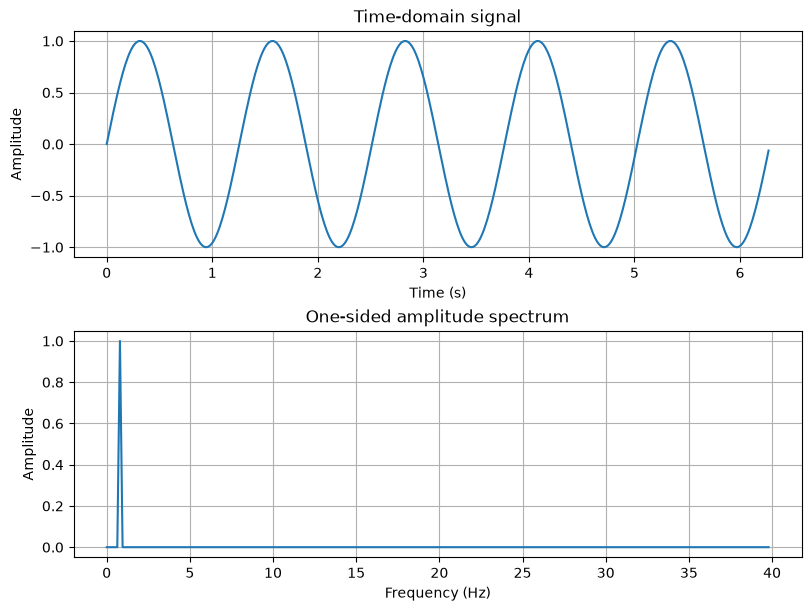

In [18]:
import numpy as np

import matplotlib.pyplot as plt



angular_frequency = 5  # rad/s

period = 2 * np.pi / angular_frequency

sample_count = 500



# Exclude the endpoint so every FFT sample is equally spaced without duplicating a period boundary.

points = np.linspace(0, 5 * period, sample_count, endpoint=False)

sample_spacing = points[1] - points[0]

data = np.sin(angular_frequency * points)



# Real-valued input has a symmetric FFT, so retain only the non-negative frequencies.

spectrum = np.fft.rfft(data)

frequencies = np.fft.rfftfreq(sample_count, d=sample_spacing)

amplitude = np.abs(spectrum) / sample_count

amplitude[1:-1] *= 2



fig, axes = plt.subplots(2, 1, figsize=(8, 6), constrained_layout=True)



axes[0].plot(points, data)

axes[0].set(xlabel="Time (s)", ylabel="Amplitude", title="Time-domain signal")

axes[0].grid(True)



axes[1].plot(frequencies, amplitude)

axes[1].set(

    xlabel="Frequency (Hz)",

    ylabel="Amplitude",

    title="One-sided amplitude spectrum",

)

axes[1].grid(True)



peak_frequency = frequencies[np.argmax(amplitude)]

print(f"FFT peak: {peak_frequency:.6f} Hz ({2 * np.pi * peak_frequency:.6f} rad/s)")

plt.show()


2.5e-12
[0.0000000e+00 2.5000000e-12 5.0000000e-12 ... 4.9999925e-06 4.9999950e-06
 4.9999975e-06]


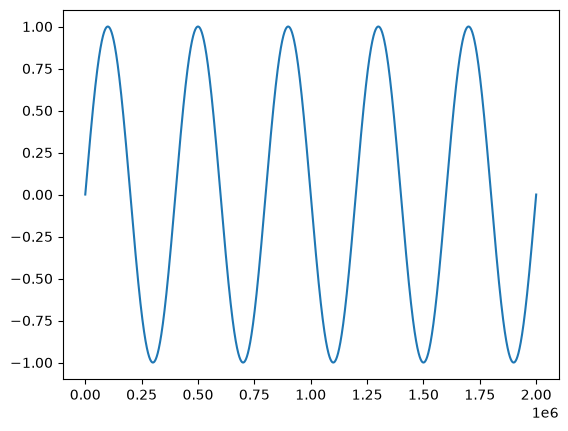

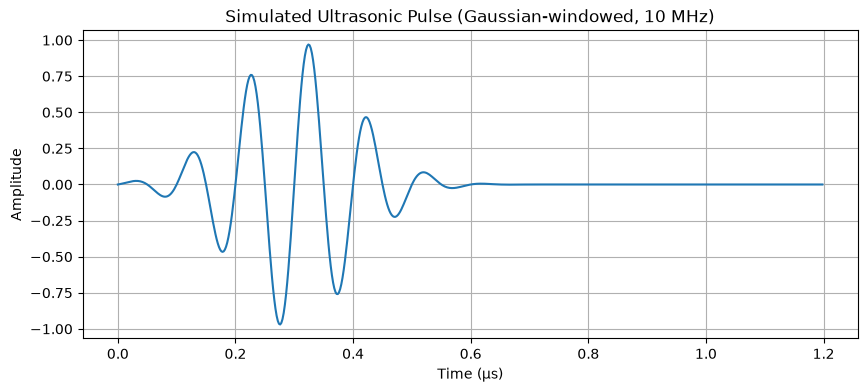

In [ ]:
import numpy as np

import matplotlib.pyplot as plt

number_of_cycles=5
frequency_hz=1*10**6

angular_frequency=2*np.pi*frequency_hz
period=1/frequency_hz
nSamples=(period*number_of_cycles)/(frequency_hz*2)

print(nSamples)
times=np.arange(0,number_of_cycles*period,nSamples)
data=np.sin(times*angular_frequency)

print(times)
plt.plot(data)



720
3.595e-05


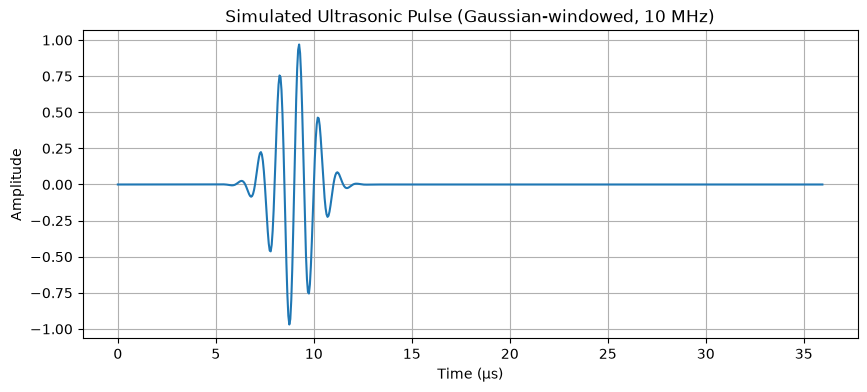

In [43]:
import numpy as np
import matplotlib.pyplot as plt

def generate_pulse(center_frequency: float, number_of_cycles: int) -> tuple[np.ndarray, np.ndarray]:
    # --- Pulse parameters ---
    fc = center_frequency              # center frequency (10 MHz probe)
    cycles = number_of_cycles          # number of cycles in the pulse
    fs = fc*20             # sampling rate (500 MHz)
    dt = 1/fs

    # --- Time vector ---
    pulse_length = cycles / fc
    t = np.arange(0, 4*pulse_length, dt)

    # --- Gaussian envelope ---
    sigma = pulse_length / number_of_cycles
    envelope = np.exp(-((t - pulse_length)**2) / (2 * sigma**2))

    # --- Broadband pulse ---
    pulse = envelope * np.sin(2 * np.pi * fc * t)

    return t, pulse

t,pulse=generate_pulse(1e6,9)

print(len(t))
print(t[-1]-t[0])
# --- Plot ---
plt.figure(figsize=(10,4))
plt.plot(t*1e6, pulse)
plt.xlabel("Time (µs)")
plt.ylabel("Amplitude")
plt.title("Simulated Ultrasonic Pulse (Gaussian-windowed, 10 MHz)")
plt.grid(True)
plt.show()
